# Cotton Disease Classification using EfficientNetB0

**CropGuard AI: AI-Powered Crop Disease Detection and Advisory System**

Final Year Project, The Islamia University of Bahawalpur (IUB)

| | |
|---|---|
| Students | Muhammad Ali Ejaz, Ahmad Siddique |
| Supervisor | Dr. Faheem Mushtaq |
| Notebook | Cotton model (one of six crop models: wheat, rice, cotton, sugarcane, potato, corn) |

## Overview

This notebook trains the cotton disease classifier used in CropGuard AI. The model takes a photo of a cotton leaf and predicts one of 4 classes: Bacterial Blight, Curl Virus, Fusarium Wilt or Healthy.

- **Dataset:** images from four different sources (two Roboflow datasets, one Kaggle dataset and the SAR-CLD-2024 dataset from Mendeley) are merged into one dataset. Exact duplicates between the sources are removed.
- **Model:** EfficientNetB0 pre-trained on ImageNet, with a small classification head on top. Images are resized to 224x224.
- **Training:** three phases with progressive unfreezing. The base model is frozen first, then unfrozen and trained with smaller learning rates.
- **Evaluation:** accuracy, per-class precision/recall/F1, confusion matrix and sample predictions on the validation set.
- **Output:** the trained model and class files that are used by the CropGuard AI backend.

The notebook was run on Kaggle with a GPU.

**Before running:** the Roboflow API key is read from Kaggle Secrets, so it is not written inside the notebook. Add a secret named `ROBOFLOW_API_KEY` in the notebook's Add-ons menu and turn it on for this notebook. The notebook also needs the two Kaggle datasets from section 1.2 attached as input.

## 1. Setup

### 1.1 Libraries

In [1]:
!pip install roboflow --quiet

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
import os
import json
import shutil
import hashlib
import zipfile
from itertools import combinations

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.2 Configuration

All paths and main settings are kept in one place so they are easy to change.

In [3]:
# Kaggle datasets that must be attached to the notebook
EXISTING_COTTON_DIR = "/kaggle/input/datasets/seroshkarim/cotton-leaf-disease-dataset"
MENDELEY_COTTON_DIR = "/kaggle/input/datasets/chaliejaz/cotton-leaf-diseases"

# Working folders
FINAL_DIR = "/kaggle/working/cotton_merged"     # merged dataset, one folder per class
OUTPUT_DIR = "/kaggle/working"

# Data settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 128
VALIDATION_SPLIT = 0.2
SEED = 42
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

tf.keras.utils.set_random_seed(SEED)

## 2. Dataset Collection

Cotton images are collected from four sources:

1. Roboflow project `cotton-disease-detectionv2` (3 classes: healthy, bacterial blight, curl virus)
2. Roboflow project `cotton-leaf-disease-gwaqa` (4 classes: the same three plus fusarium wilt)
3. A Kaggle cotton leaf disease dataset by seroshkarim (4 classes)
4. The SAR-CLD-2024 dataset from Mendeley (4 classes, with severity folders), stored as a Kaggle dataset

### 2.1 Downloading the Roboflow datasets

In [4]:
rf = Roboflow(api_key=UserSecretsClient().get_secret("ROBOFLOW_API_KEY"))

# Source 1: 3 classes
project_a = rf.workspace("h-jintr").project("cotton-disease-detectionv2")
dataset_a = project_a.version(1).download("folder")
print("Source 1 downloaded to:", dataset_a.location)

# Source 2: 4 classes
project_b = rf.workspace("cottonleafdisease-nvr42").project("cotton-leaf-disease-gwaqa")
dataset_b = project_b.version(1).download("folder")
print("Source 2 downloaded to:", dataset_b.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cotton-disease-detectionv2-1 in folder:: 100%|██████████| 2612/2612 [00:00<00:00, 7484.66it/s]

Source 1 downloaded to: /kaggle/working/cotton-disease-detectionv2-1
loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to cotton-leaf-disease-1 in folder:: 100%|██████████| 3833/3833 [00:00<00:00, 12065.68it/s]

Source 2 downloaded to: /kaggle/working/cotton-leaf-disease-1


### 2.2 Folder structure of the sources

The sources use different folder layouts, so the structure is printed first. The numbers in brackets are the number of files directly inside each folder.

In [5]:
def show_tree(path, max_depth=3, prefix=""):
    if max_depth < 0:
        return
    for entry in sorted(os.listdir(path)):
        full = os.path.join(path, entry)
        if os.path.isdir(full):
            n_files = len([f for f in os.listdir(full) if os.path.isfile(os.path.join(full, f))])
            print(f"{prefix}{entry}/  ({n_files} files)")
            show_tree(full, max_depth - 1, prefix + "    ")


print("=== Source 1: Roboflow cotton-disease-detectionv2 ===")
show_tree(dataset_a.location)

print("\n=== Source 2: Roboflow cotton-leaf-disease-gwaqa ===")
show_tree(dataset_b.location)

print("\n=== Source 3: Kaggle dataset (seroshkarim) ===")
show_tree(EXISTING_COTTON_DIR)

print("\n=== Source 4: Mendeley SAR-CLD-2024 ===")
show_tree(MENDELEY_COTTON_DIR, max_depth=4)

=== Source 1: Roboflow cotton-disease-detectionv2 ===
test/  (0 files)
    bacterial_blight/  (35 files)
    curl_virus/  (37 files)
    healthy/  (34 files)
train/  (0 files)
    bacterial_blight/  (924 files)
    curl_virus/  (825 files)
    healthy/  (531 files)
valid/  (0 files)
    bacterial_blight/  (88 files)
    curl_virus/  (67 files)
    healthy/  (57 files)

=== Source 2: Roboflow cotton-leaf-disease-gwaqa ===
test/  (0 files)
    bacterial_blight/  (47 files)
    curl_virus/  (29 files)
    fussarium_wilt/  (38 files)
    healthy/  (42 files)
train/  (0 files)
    bacterial_blight/  (921 files)
    curl_virus/  (777 files)
    fussarium_wilt/  (828 files)
    healthy/  (813 files)
valid/  (0 files)
    bacterial_blight/  (77 files)
    curl_virus/  (91 files)
    fussarium_wilt/  (81 files)
    healthy/  (72 files)

=== Source 3: Kaggle dataset (seroshkarim) ===
cotton/  (0 files)
    bacterial_blight/  (448 files)
    curl_virus/  (418 files)
    fussarium_wilt/  (419 file

### 2.3 Making the class names consistent

The sources write the class names in different ways (for example `bacterial_blight`, `bacterial blight` and even the spelling `fussarium_wilt`). All of them are mapped to four standard names: `BacterialBlight`, `CurlVirus`, `FusariumWilt` and `Healthy`.

In [6]:
CLASS_NAME_MAP = {
    "healthy": "Healthy",
    "bacterialblight": "BacterialBlight",
    "curlvirus": "CurlVirus",
    "fusariumwilt": "FusariumWilt",
    "fussariumwilt": "FusariumWilt",
}


def normalize_class_name(folder_name):
    # lower case and remove spaces, underscores and dashes before comparing
    key = folder_name.strip().lower().replace("-", "").replace(" ", "").replace("_", "")
    if key in CLASS_NAME_MAP:
        return CLASS_NAME_MAP[key]
    print(f"Warning: unrecognized class folder '{folder_name}', kept as it is")
    return folder_name.strip()

### 2.4 Finding the image folders

This function walks through a source and returns the folders that contain images for each class. It handles the three layouts that appear in our sources:

- flat folders: `ClassName/*.jpg`
- split folders: `train/ClassName/*.jpg`
- severity folders (Mendeley): `ClassName/mild/*.jpg`

The Mendeley dataset also has `augment_result` folders with synthetic copies. These are skipped, because they are not new images.

In [7]:
def find_class_folders(root_dir, skip_names=("train", "valid", "test", "images", "cotton", "cotton-original-augmented")):
    severity_words = ("mild", "moderate", "severe", "critical", "early", "late")
    class_folders = {}

    for dirpath, dirnames, filenames in os.walk(root_dir):
        image_files = [f for f in filenames if f.lower().endswith(IMAGE_EXTENSIONS)]
        if len(image_files) == 0:
            continue

        folder_name = os.path.basename(dirpath)
        if folder_name.lower() == "augment_result":
            continue

        parent_name = os.path.basename(os.path.dirname(dirpath))
        gparent_name = os.path.basename(os.path.dirname(os.path.dirname(dirpath)))

        if folder_name.lower() in severity_words and parent_name:
            effective_name = parent_name
        elif parent_name.lower() in severity_words and gparent_name:
            effective_name = gparent_name
        elif folder_name.lower() in skip_names:
            continue
        else:
            effective_name = folder_name

        normalized = normalize_class_name(effective_name)
        class_folders.setdefault(normalized, []).append(dirpath)

    return class_folders


def count_images(folder):
    return len([f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTENSIONS)])


sources = {
    "roboflow_a": find_class_folders(dataset_a.location),
    "roboflow_b": find_class_folders(dataset_b.location),
    "existing": find_class_folders(EXISTING_COTTON_DIR),
    "mendeley": find_class_folders(MENDELEY_COTTON_DIR),
}

for name, class_folders in sources.items():
    print(f"=== {name} ===")
    for cls, folders in class_folders.items():
        total = sum(count_images(p) for p in folders)
        print(f"  {cls}: {total} images in {len(folders)} folder(s)")

=== roboflow_a ===
  CurlVirus: 929 images in 3 folder(s)
  BacterialBlight: 1047 images in 3 folder(s)
  Healthy: 622 images in 3 folder(s)
=== roboflow_b ===
  CurlVirus: 897 images in 3 folder(s)
  BacterialBlight: 1045 images in 3 folder(s)
  FusariumWilt: 947 images in 3 folder(s)
  Healthy: 927 images in 3 folder(s)
=== existing ===
  BacterialBlight: 448 images in 1 folder(s)
  CurlVirus: 417 images in 1 folder(s)
  FusariumWilt: 419 images in 1 folder(s)
  Healthy: 425 images in 1 folder(s)
=== mendeley ===
  BacterialBlight: 119 images in 3 folder(s)
  CurlVirus: 25 images in 3 folder(s)
  FusariumWilt: 47 images in 3 folder(s)
  Healthy: 789 images in 1 folder(s)


### 2.5 Checking for duplicates between sources

The same photo can appear in more than one source. To find these, every image gets a hash (a short fingerprint made from the first 64 KB of the file), and the hashes are compared between each pair of sources. Only images with exactly the same file content are detected this way.

In [8]:
def file_hash(filepath):
    h = hashlib.md5()
    with open(filepath, "rb") as f:
        h.update(f.read(65536))
    return h.hexdigest()


def hash_all_images(folder_list):
    hashes = {}
    for folder in folder_list:
        for fname in os.listdir(folder):
            if fname.lower().endswith(IMAGE_EXTENSIONS):
                fpath = os.path.join(folder, fname)
                try:
                    hashes[file_hash(fpath)] = fpath
                except Exception:
                    pass
    return hashes


all_classes = sorted(set(cls for class_folders in sources.values() for cls in class_folders))

for cls in all_classes:
    hashes = {name: hash_all_images(class_folders.get(cls, [])) for name, class_folders in sources.items()}

    print(f"\n{cls}")
    print("  unique images per source:", {name: len(h) for name, h in hashes.items()})
    for a, b in combinations(hashes, 2):
        shared = len(set(hashes[a]) & set(hashes[b]))
        if shared > 0:
            print(f"  duplicates between {a} and {b}: {shared}")


BacterialBlight
  unique images per source: {'roboflow_a': 1047, 'roboflow_b': 1045, 'existing': 432, 'mendeley': 119}

CurlVirus
  unique images per source: {'roboflow_a': 929, 'roboflow_b': 897, 'existing': 379, 'mendeley': 25}
  duplicates between existing and mendeley: 11

FusariumWilt
  unique images per source: {'roboflow_a': 0, 'roboflow_b': 947, 'existing': 395, 'mendeley': 47}
  duplicates between existing and mendeley: 11

Healthy
  unique images per source: {'roboflow_a': 622, 'roboflow_b': 927, 'existing': 384, 'mendeley': 789}


### 2.6 Merging the sources

All sources are merged into one folder per class. If the same image appears in more than one source, only the first copy is kept (the sources are processed in this order: Kaggle dataset, Roboflow 1, Roboflow 2, Mendeley). The source name is added to each file name so that files never overwrite each other.

In [9]:
os.makedirs(FINAL_DIR, exist_ok=True)

source_order = ["existing", "roboflow_a", "roboflow_b", "mendeley"]
final_counts = {}

for cls in all_classes:
    cls_out_dir = os.path.join(FINAL_DIR, cls)
    os.makedirs(cls_out_dir, exist_ok=True)

    seen_hashes = set()
    counts = {name: 0 for name in source_order}

    for name in source_order:
        for folder in sources[name].get(cls, []):
            for fname in os.listdir(folder):
                if not fname.lower().endswith(IMAGE_EXTENSIONS):
                    continue
                src = os.path.join(folder, fname)
                try:
                    h = file_hash(src)
                except Exception:
                    continue
                if h not in seen_hashes:
                    dst = os.path.join(cls_out_dir, f"{name}_{counts[name]}_{fname}")
                    shutil.copy2(src, dst)
                    seen_hashes.add(h)
                    counts[name] += 1

    final_counts[cls] = sum(counts.values())
    print(f"{cls}: {counts}  ->  total {final_counts[cls]}")

print(f"\nMerged dataset: {sum(final_counts.values())} images in {len(final_counts)} classes")

BacterialBlight: {'existing': 432, 'roboflow_a': 1047, 'roboflow_b': 1045, 'mendeley': 119}  ->  total 2643
CurlVirus: {'existing': 379, 'roboflow_a': 929, 'roboflow_b': 897, 'mendeley': 14}  ->  total 2219
FusariumWilt: {'existing': 395, 'roboflow_a': 0, 'roboflow_b': 947, 'mendeley': 36}  ->  total 1378
Healthy: {'existing': 384, 'roboflow_a': 622, 'roboflow_b': 927, 'mendeley': 789}  ->  total 2722

Merged dataset: 8962 images in 4 classes


### 2.7 Removing corrupt images

In [10]:
def remove_corrupt_images(root_dir):
    checked, removed = 0, 0
    for cls in os.listdir(root_dir):
        cls_dir = os.path.join(root_dir, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            checked += 1
            try:
                tf.image.decode_image(tf.io.read_file(fpath))
            except Exception:
                os.remove(fpath)
                removed += 1
    print(f"Checked {checked} images, removed {removed} corrupt files")


remove_corrupt_images(FINAL_DIR)

I0000 00:00:1793088176.345076      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793088176.350157      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Checked 8962 images, removed 0 corrupt files


### 2.8 Class distribution

BacterialBlight: 2643
CurlVirus: 2219
FusariumWilt: 1378
Healthy: 2722

Total: 8962 images in 4 classes


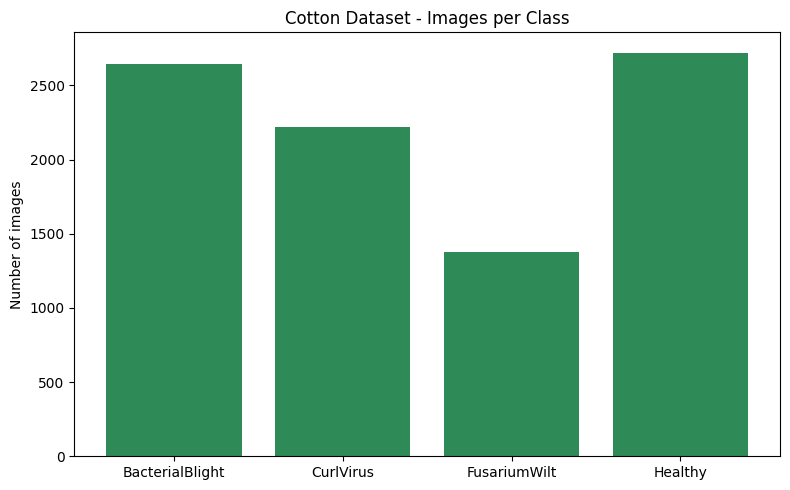

In [11]:
class_counts = {cls: count_images(os.path.join(FINAL_DIR, cls)) for cls in sorted(os.listdir(FINAL_DIR))}

for cls, n in class_counts.items():
    print(f"{cls}: {n}")
print(f"\nTotal: {sum(class_counts.values())} images in {len(class_counts)} classes")

plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values(), color="seagreen")
plt.ylabel("Number of images")
plt.title("Cotton Dataset - Images per Class")
plt.tight_layout()
plt.show()

Fusarium Wilt has fewer images than the other classes, so class weights are used during training (section 4).

## 3. Loading the Data

`image_dataset_from_directory` reads the images from the merged folder and splits them 80% for training and 20% for validation. The same seed is used for both calls so the two subsets do not overlap.

In [12]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    FINAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=VALIDATION_SPLIT,
    subset="training", seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    FINAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=VALIDATION_SPLIT,
    subset="validation", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 8962 files belonging to 4 classes.
Using 7170 files for training.
Found 8962 files belonging to 4 classes.
Using 1792 files for validation.
Classes: ['BacterialBlight', 'CurlVirus', 'FusariumWilt', 'Healthy']
Number of classes: 4


## 4. Class Weights

Because of the class imbalance, each class gets a weight that is higher for smaller classes. This makes mistakes on rare classes (like Fusarium Wilt) cost more during training.

In [13]:
labels_flat = []
for i, cls in enumerate(class_names):
    labels_flat.extend([i] * count_images(os.path.join(FINAL_DIR, cls)))
labels_flat = np.array(labels_flat)

cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}

for i, cls in enumerate(class_names):
    print(f"{cls}: {class_weight_dict[i]:.3f}")

BacterialBlight: 0.848
CurlVirus: 1.010
FusariumWilt: 1.626
Healthy: 0.823


## 5. Augmentation and Preprocessing

Random flips, rotation, zoom, brightness and contrast are applied to the training images only. This helps the model handle different camera angles and lighting. The validation images are only preprocessed, not augmented, so the validation score stays consistent.

In [14]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")


def prep_train(img, lbl):
    return preprocess_input(augmentation(img)), lbl


def prep_val(img, lbl):
    return preprocess_input(img), lbl


train_ds_p = train_ds.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p = val_ds.map(prep_val, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

## 6. Model

EfficientNetB0 is used as the base model with ImageNet weights and without its original top layer. On top of it we add:

- Global average pooling to turn the feature maps into one vector
- Batch normalization
- Dropout (0.4) to reduce overfitting
- A dense softmax layer with one output per class

The base model starts frozen so that only the new head is trained in the first phase.

In [15]:
base_model = EfficientNetB0(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs, name="cotton_efficientnetb0")
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cotton_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,059,815 (15.49 MB)

 Trainable params: 7,684 (30.02 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

### 6.1 Callbacks

- **EarlyStopping:** stops a phase when validation accuracy stops improving and goes back to the best weights.
- **ModelCheckpoint:** saves the model with the best validation accuracy to `cotton_best.keras`.
- **ReduceLROnPlateau:** lowers the learning rate when validation loss stops improving.

The same callbacks are used for all three phases.

In [16]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=3, restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    f"{OUTPUT_DIR}/cotton_best.keras", monitor="val_accuracy", save_best_only=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6
)

callbacks = [early_stop, checkpoint, reduce_lr]

## 7. Training

Training is done in three phases. The learning rate gets smaller in every phase, so the pre-trained weights are changed gently once the base model is unfrozen.

| Phase | Base model | Learning rate | Max epochs |
|---|---|---|---|
| 1 | Frozen | 1e-3 | 5 |
| 2 | Fully unfrozen | 1e-4 | 10 |
| 3 | Fully unfrozen | 3e-5 | 15 |

### Phase 1: Frozen base

Only the new classification head is trained. This gives the head sensible weights before the base model is touched.

In [17]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])

h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=5,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 1 best validation accuracy: {max(h1.history['val_accuracy']) * 100:.2f}%")

Epoch 1/5


2026-10-27 08:04:12.541821: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:04:12.725718: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:04:13.245718: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:04:13.397640: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:04:14.248022: E external/local_xla/xla/stream_

56/57 ━━━━━━━━━━━━━━━━━━━━ 0s 691ms/step - accuracy: 0.5006 - loss: 1.4784

2026-10-27 08:05:06.295210: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:05:06.429264: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:05:06.738967: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:05:06.880603: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:05:07.635667: E external/local_xla/xla/stream_

57/57 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.6649 - loss: 0.9668 - val_accuracy: 0.8677 - val_loss: 0.5163 - learning_rate: 0.0010
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 51s 859ms/step - accuracy: 0.8569 - loss: 0.4257 - val_accuracy: 0.9330 - val_loss: 0.3200 - learning_rate: 0.0010
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 52s 866ms/step - accuracy: 0.8954 - loss: 0.3029 - val_accuracy: 0.9660 - val_loss: 0.2089 - learning_rate: 0.0010
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 82s 869ms/step - accuracy: 0.9029 - loss: 0.2842 - val_accuracy: 0.9682 - val_loss: 0.1573 - learning_rate: 0.0010
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 52s 867ms/step - accuracy: 0.9180 - loss: 0.2497 - val_accuracy: 0.9766 - val_loss: 0.1169 - learning_rate: 0.0010
Phase 1 best validation accuracy: 97.66%


### Phase 2: Full fine-tuning (lr = 1e-4)

The whole base model is unfrozen so the pre-trained features can adapt to cotton leaves.

In [18]:
base_model.trainable = True

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])

h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 2 best validation accuracy: {max(h2.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-27 08:10:07.103545: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:10:07.331518: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:10:11.719740: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[128,96,113,113]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,96,115,115]{3,2,1,0}, f32[96,1,3,3]{3,2,1,0}), window={size=3x3}, dim_labels=bf01_oi01->bf01, feature_group_count=96, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_al

56/57 ━━━━━━━━━━━━━━━━━━━━ 0s 731ms/step - accuracy: 0.7830 - loss: 0.5995

2026-10-27 08:11:37.019248: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:11:37.154104: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:11:37.288002: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:11:40.059973: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:11:40.193586: E external/local_xla/xla/stream_

57/57 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.8675 - loss: 0.3760 - val_accuracy: 0.9827 - val_loss: 0.0731 - learning_rate: 1.0000e-04
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 54s 898ms/step - accuracy: 0.9515 - loss: 0.1500 - val_accuracy: 0.9872 - val_loss: 0.0618 - learning_rate: 1.0000e-04
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 54s 897ms/step - accuracy: 0.9675 - loss: 0.1054 - val_accuracy: 0.9877 - val_loss: 0.0593 - learning_rate: 1.0000e-04
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 52s 877ms/step - accuracy: 0.9736 - loss: 0.0886 - val_accuracy: 0.9877 - val_loss: 0.0527 - learning_rate: 1.0000e-04
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 53s 875ms/step - accuracy: 0.9741 - loss: 0.0841 - val_accuracy: 0.9877 - val_loss: 0.0523 - learning_rate: 1.0000e-04
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 53s 880ms/step - accuracy: 0.9781 - loss: 0.0716 - val_accuracy: 0.9877 - val_loss: 0.0496 - learning_rate: 1.0000e-04
Phase 2 best validation accuracy: 98.77%


### Phase 3: Extended fine-tuning (lr = 3e-5)

Training continues with a smaller learning rate for finer updates.

In [19]:
model.compile(optimizer=keras.optimizers.Adam(3e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 3 best validation accuracy: {max(h3.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 154s 1s/step - accuracy: 0.9721 - loss: 0.0828 - val_accuracy: 0.9883 - val_loss: 0.0509 - learning_rate: 3.0000e-05
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 53s 877ms/step - accuracy: 0.9748 - loss: 0.0766 - val_accuracy: 0.9883 - val_loss: 0.0495 - learning_rate: 3.0000e-05
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 52s 871ms/step - accuracy: 0.9777 - loss: 0.0740 - val_accuracy: 0.9872 - val_loss: 0.0494 - learning_rate: 3.0000e-05
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 52s 874ms/step - accuracy: 0.9789 - loss: 0.0708 - val_accuracy: 0.9877 - val_loss: 0.0479 - learning_rate: 3.0000e-05
Phase 3 best validation accuracy: 98.83%


### 7.1 Training curves

The plots below join all three phases. The dashed vertical lines show where a new phase starts.

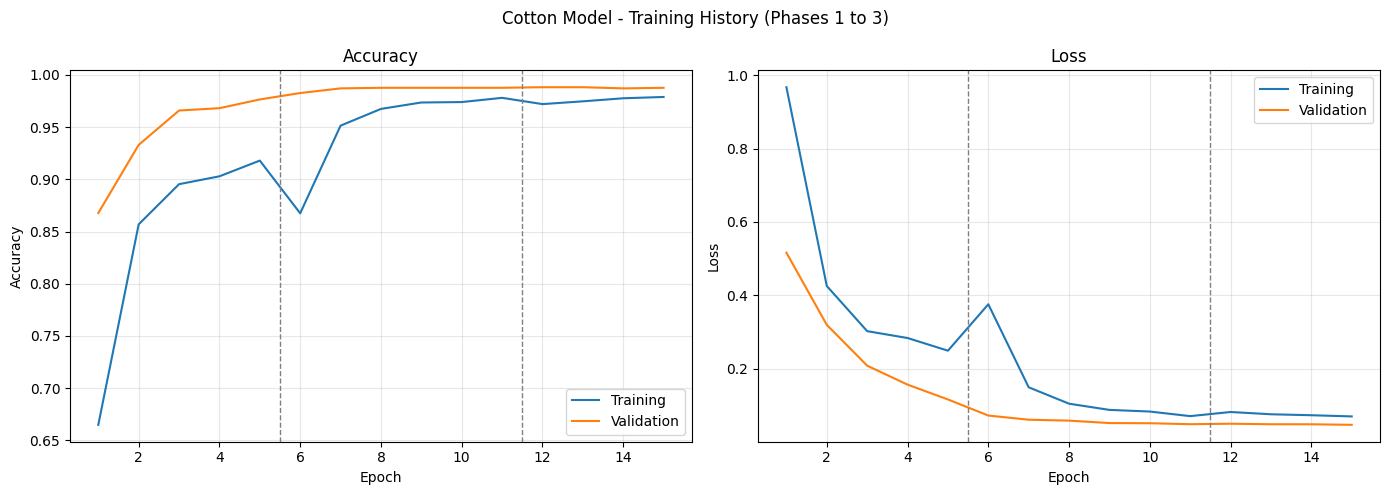

In [20]:
histories = [h1, h2, h3]

train_acc, val_acc, train_loss, val_loss = [], [], [], []
phase_ends = []
for h in histories:
    train_acc += h.history["accuracy"]
    val_acc += h.history["val_accuracy"]
    train_loss += h.history["loss"]
    val_loss += h.history["val_loss"]
    phase_ends.append(len(train_acc))

epochs_range = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_acc, label="Training")
axes[0].plot(epochs_range, val_acc, label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].plot(epochs_range, train_loss, label="Training")
axes[1].plot(epochs_range, val_loss, label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

for ax in axes:
    for end in phase_ends[:-1]:
        ax.axvline(end + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Cotton Model - Training History (Phases 1 to 3)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/cotton_training_curves.png", dpi=150)
plt.show()

## 8. Evaluation

The model is evaluated on the validation set (20% of the images, never used for weight updates). Precision, recall and F1-score are reported for every class, followed by the confusion matrix.

In [21]:
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

val_accuracy = np.mean(y_true == y_pred)
print(f"Validation accuracy: {val_accuracy * 100:.2f}%  ({len(y_true)} images)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

2026-10-27 08:22:00.494879: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:22:00.637880: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:22:00.992168: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:22:01.133685: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 08:22:01.933569: E external/local_xla/xla/stream_

Validation accuracy: 98.83%  (1792 images)

                 precision    recall  f1-score   support

BacterialBlight     1.0000    0.9767    0.9882       515
      CurlVirus     1.0000    0.9936    0.9968       466
   FusariumWilt     0.9924    0.9776    0.9850       268
        Healthy     0.9662    1.0000    0.9828       543

       accuracy                         0.9883      1792
      macro avg     0.9897    0.9870    0.9882      1792
   weighted avg     0.9886    0.9883    0.9883      1792



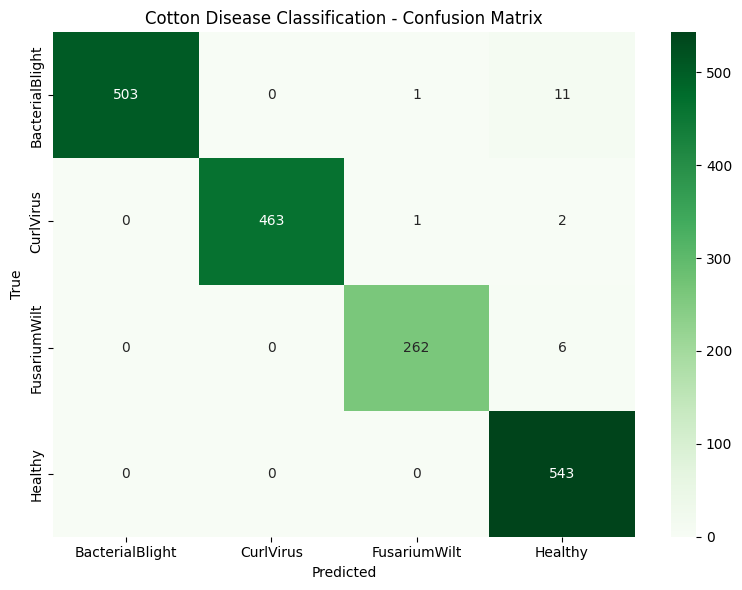

In [22]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Cotton Disease Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/cotton_confusion_matrix.png", dpi=150)
plt.show()

### 8.1 Sample predictions

A batch of validation images with the true label, the predicted label and the model's confidence. Green titles are correct predictions and red titles are mistakes.

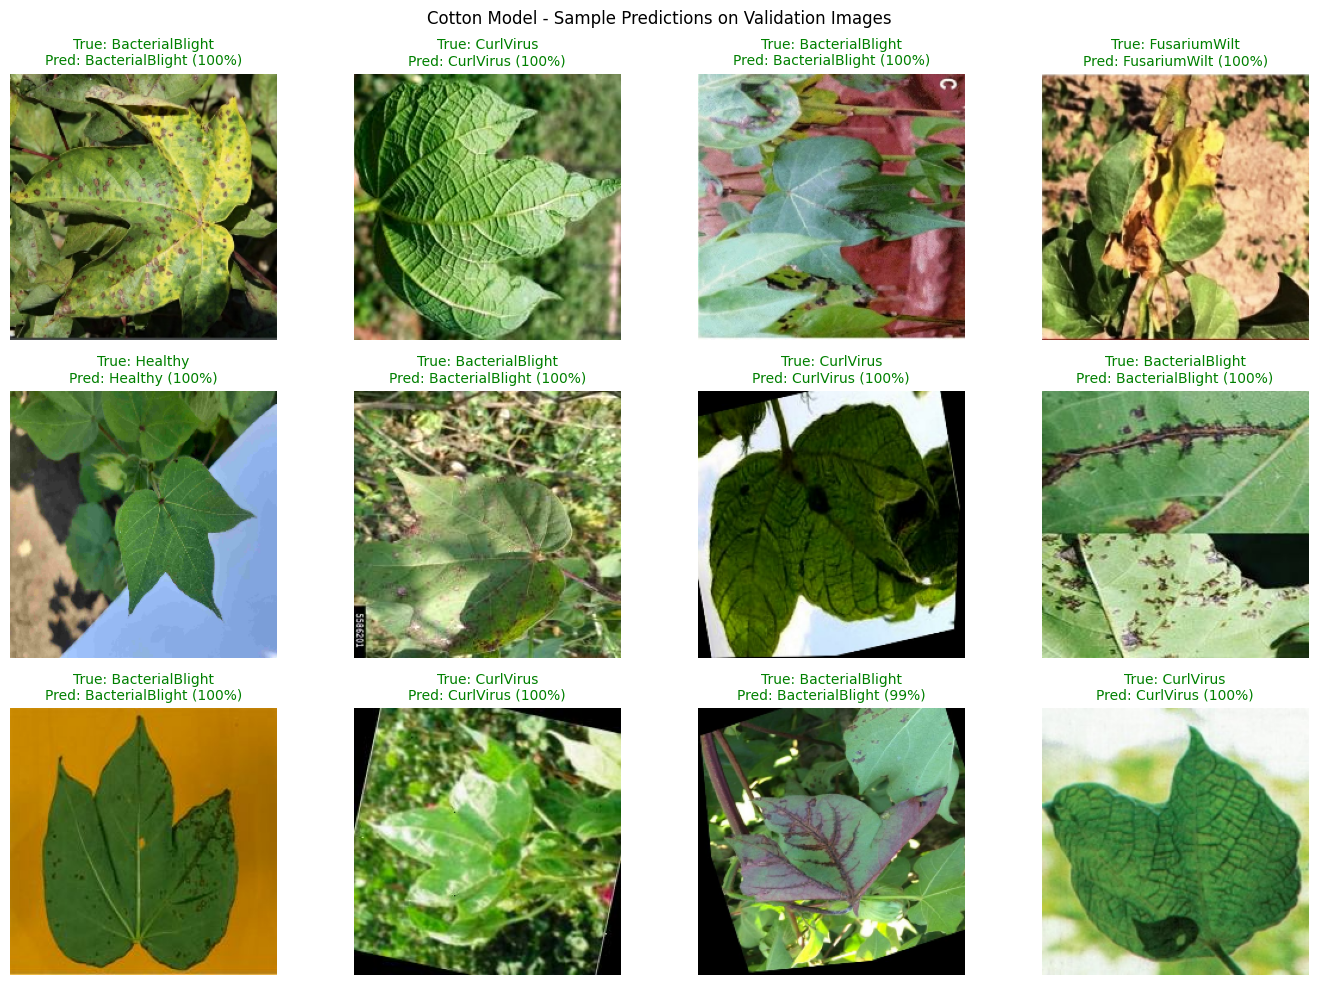

In [23]:
sample_images, sample_labels = next(iter(val_ds))
sample_probs = model.predict(preprocess_input(sample_images), verbose=0)

sample_true = np.argmax(sample_labels.numpy(), axis=1)
sample_pred = np.argmax(sample_probs, axis=1)

plt.figure(figsize=(14, 10))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))
    plt.axis("off")

    confidence = sample_probs[i][sample_pred[i]] * 100
    correct = sample_true[i] == sample_pred[i]
    plt.title(f"True: {class_names[sample_true[i]]}\nPred: {class_names[sample_pred[i]]} ({confidence:.0f}%)",
              fontsize=10, color="green" if correct else "red")

plt.suptitle("Cotton Model - Sample Predictions on Validation Images")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/cotton_sample_predictions.png", dpi=150)
plt.show()

## 9. Saving the Model

The final model is saved together with two JSON files that the CropGuard AI backend needs:

- `cotton_class_names.json`: the class labels in the same order as the model outputs, in the form `cotton__<disease>`
- `cotton_class_map.json`: maps each label to the crop name and a readable disease name

Everything is then packed into one zip file.

In [24]:
model.save(f"{OUTPUT_DIR}/cotton_final.keras")
size_mb = os.path.getsize(f"{OUTPUT_DIR}/cotton_final.keras") / 1024 / 1024
print(f"Model saved ({size_mb:.1f} MB)")

Model saved (47.1 MB)


In [25]:
DISEASE_DISPLAY_NAMES = {
    "BacterialBlight": "Bacterial Blight",
    "CurlVirus": "Curl Virus",
    "FusariumWilt": "Fusarium Wilt",
    "Healthy": "Healthy",
}

cotton_class_map = {}
production_class_names = []

for cls in class_names:
    key = "cotton__" + cls.lower()
    production_class_names.append(key)
    cotton_class_map[key] = {"crop": "Cotton", "disease": DISEASE_DISPLAY_NAMES.get(cls, cls)}

with open(f"{OUTPUT_DIR}/cotton_class_map.json", "w") as f:
    json.dump(cotton_class_map, f, indent=2)
with open(f"{OUTPUT_DIR}/cotton_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)

print(json.dumps(cotton_class_map, indent=2))

{
  "cotton__bacterialblight": {
    "crop": "Cotton",
    "disease": "Bacterial Blight"
  },
  "cotton__curlvirus": {
    "crop": "Cotton",
    "disease": "Curl Virus"
  },
  "cotton__fusariumwilt": {
    "crop": "Cotton",
    "disease": "Fusarium Wilt"
  },
  "cotton__healthy": {
    "crop": "Cotton",
    "disease": "Healthy"
  }
}


In [26]:
files = [
    f"{OUTPUT_DIR}/cotton_final.keras",
    f"{OUTPUT_DIR}/cotton_best.keras",
    f"{OUTPUT_DIR}/cotton_class_map.json",
    f"{OUTPUT_DIR}/cotton_class_names.json",
    f"{OUTPUT_DIR}/cotton_confusion_matrix.png",
    f"{OUTPUT_DIR}/cotton_training_curves.png",
    f"{OUTPUT_DIR}/cotton_sample_predictions.png",
]

zip_path = f"{OUTPUT_DIR}/cotton_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
            print(f"added {os.path.basename(f)} ({os.path.getsize(f) / 1024 / 1024:.1f} MB)")
        else:
            print(f"missing: {f}")

print(f"\nPackage: {zip_path} ({os.path.getsize(zip_path) / 1024 / 1024:.1f} MB)")

added cotton_final.keras (47.1 MB)
added cotton_best.keras (47.1 MB)
added cotton_class_map.json (0.0 MB)
added cotton_class_names.json (0.0 MB)
added cotton_confusion_matrix.png (0.1 MB)
added cotton_training_curves.png (0.1 MB)
added cotton_sample_predictions.png (2.9 MB)

Package: /kaggle/working/cotton_model_package.zip (97.2 MB)


## 10. Summary and Limitations

**Summary**

- Cotton leaf images from four sources were merged (exact duplicates removed) and used to fine-tune an EfficientNetB0 model for 4 classes, using three training phases with decreasing learning rates.
- Class weights were used to handle the imbalance between classes, and augmentation was applied to the training images only.
- The final validation accuracy, per-class scores, confusion matrix and sample predictions are shown in section 8.
- The saved model and class files are used in the CropGuard AI website and mobile app.

**Limitations**

- The reported accuracy is validation accuracy. The same validation set was used for early stopping and for choosing the best checkpoint, and there is no separate test set, so the score can be slightly higher than what completely unseen images would give.
- The sources were merged and split again randomly. Roboflow dataset versions can contain augmented copies of the same photo (flipped, rotated or color-changed). The duplicate check in section 2.5 only finds files with exactly the same content, so it cannot find these copies. If copies of one photo end up in both training and validation, the accuracy looks better than it really is.
- The four sources were collected with different cameras and backgrounds. The model may partly learn the style of a source instead of only the disease.
- The images may be different from photos that farmers take with their phones in the field (lighting, background, camera quality), so accuracy in real use can be lower.

**Future work**

- Split the data by original photo, or use the original validation and test folders of the Roboflow datasets, so that no copy of a training image appears in validation.
- Test the model on a separate set of cotton images collected from fields in Pakistan.